# UBOS District Population Forecast

This notebook analyzes ten years of population estimates (2015–2024), compares forecasting approaches, and estimates primary-school classroom needs through 2029. Population values are in **thousands of people**.

Kampala, Wakiso, and Gulu use the supplied data. Mbarara and Mbale are **illustrative examples**, not official UBOS estimates. Run cells from top to bottom from the repository root.

## Learning objectives
- Summarize data with the Python statistics module and NumPy.
- Calculate annual growth and compound annual growth rate (CAGR).
- Validate models on held-out 2022–2024 data.
- Forecast 2025–2029 population and estimate classroom needs.
- Explain model limitations and uncertainty.


## 1. Imports and forecasting classes

The district and forecasting classes live separately in `src/ubos.py`. Keeping reusable OOP code separate lets this notebook focus on analysis and interpretation.


In [1]:
from __future__ import annotations

import math
import statistics

import matplotlib.pyplot as plt
import numpy as np

from src.ubos import (
    CAGRGrowthForecaster,
    DistrictPopulation,
    FibonacciRatioForecaster,
    LinearTrendForecaster,
)


## 2. Enter and inspect the data

The supplied series are population estimates in thousands. Mbarara and Mbale are added illustrative districts. We use a chronological split: 2015–2021 for training and 2022–2024 for validation.


In [2]:
years = np.arange(2015, 2025)
districts = [
    DistrictPopulation(years, [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], "Kampala"),
    DistrictPopulation(years, [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], "Wakiso"),
    DistrictPopulation(years, [320, 330, 345, 360, 375, 390, 410, 430, 455, 480], "Gulu"),
    DistrictPopulation(years, [450, 465, 480, 500, 520, 545, 570, 600, 630, 660], "Mbarara (illustrative)"),
    DistrictPopulation(years, [500, 515, 535, 560, 590, 620, 655, 695, 740, 790], "Mbale (illustrative)"),
]
train_size = 7
training_years = years[:train_size]
test_years = years[train_size:]
forecast_years = np.arange(2025, 2030)

for district in districts:
    print(district)


DistrictPopulation(name='Kampala', years=2015-2024, observations=10)
DistrictPopulation(name='Wakiso', years=2015-2024, observations=10)
DistrictPopulation(name='Gulu', years=2015-2024, observations=10)
DistrictPopulation(name='Mbarara (illustrative)', years=2015-2024, observations=10)
DistrictPopulation(name='Mbale (illustrative)', years=2015-2024, observations=10)


## 3. Descriptive statistics

Mean and median describe the center of a series; variance and standard deviation describe its spread. `statistics.variance` uses the sample denominator **n − 1**, while `np.var` defaults to **n**. NumPy's `ddof` (“delta degrees of freedom”) is subtracted from *n*, so `ddof=1` matches sample variance and `ddof=0` calculates population variance.


In [3]:
summary_statistics = {}
for district in districts:
    values = district.population.tolist()
    summary_statistics[district.district_name] = {
        "statistics module": {
            "mean": statistics.mean(values),
            "median": statistics.median(values),
            "variance": statistics.variance(values),
            "standard deviation": statistics.stdev(values),
        },
        "NumPy (ddof=0)": {
            "mean": float(np.mean(district.population)),
            "median": float(np.median(district.population)),
            "variance": float(np.var(district.population)),
            "standard deviation": float(np.std(district.population)),
        },
        "NumPy (ddof=1)": {
            "variance": float(np.var(district.population, ddof=1)),
            "standard deviation": float(np.std(district.population, ddof=1)),
        },
    }
    print(f"\n{district.district_name} (population in thousands)")
    for method, values_by_stat in summary_statistics[district.district_name].items():
        print(f"  {method}: {values_by_stat}")
    assert np.isclose(
        summary_statistics[district.district_name]["statistics module"]["variance"],
        summary_statistics[district.district_name]["NumPy (ddof=1)"]["variance"],
    )



Kampala (population in thousands)
  statistics module: {'mean': 1477.0, 'median': 1460.0, 'variance': 42601.11111111111, 'standard deviation': 206.40036606341354}
  NumPy (ddof=0): {'mean': 1477.0, 'median': 1460.0, 'variance': 38341.0, 'standard deviation': 195.8085799958725}
  NumPy (ddof=1): {'variance': 42601.11111111111, 'standard deviation': 206.40036606341354}

Wakiso (population in thousands)
  statistics module: {'mean': 1280.0, 'median': 1260.0, 'variance': 60066.666666666664, 'standard deviation': 245.085019262024}
  NumPy (ddof=0): {'mean': 1280.0, 'median': 1260.0, 'variance': 54060.0, 'standard deviation': 232.50806437627062}
  NumPy (ddof=1): {'variance': 60066.666666666664, 'standard deviation': 245.085019262024}

Gulu (population in thousands)
  statistics module: {'mean': 389.5, 'median': 382.5, 'variance': 2885.8333333333335, 'standard deviation': 53.71995284187555}
  NumPy (ddof=0): {'mean': 389.5, 'median': 382.5, 'variance': 2597.25, 'standard deviation': 50.9632

## 4. Year-on-year growth and CAGR

Year-on-year growth measures each annual percentage change. CAGR is the constant annual rate connecting the first and last population values. The 2015–2024 period contains **nine elapsed years**. CAGR smooths annual fluctuations and is useful for comparing relative growth between districts.


In [4]:
growth_results = {}
for district in districts:
    rates = (district.population[1:] / district.population[:-1] - 1) * 100
    elapsed_years = district.years[-1] - district.years[0]
    cagr = ((district.population[-1] / district.population[0]) ** (1 / elapsed_years) - 1) * 100
    growth_results[district.district_name] = {"annual rates": rates, "CAGR": float(cagr)}
    yearly = ", ".join(
        f"{year}: {rate:.2f}%"
        for year, rate in zip(district.years[1:], rates)
    )
    print(f"\n{district.district_name}: {yearly}")
    print(f"  CAGR, 2015–2024: {cagr:.2f}%")

fastest_district = max(growth_results, key=lambda name: growth_results[name]["CAGR"])
print(f"\nFastest relative growth: {fastest_district} ({growth_results[fastest_district]['CAGR']:.2f}% CAGR)")



Kampala: 2016: 4.17%, 2017: 4.00%, 2018: 3.85%, 2019: 5.19%, 2020: 5.63%, 2021: 5.33%, 2022: 4.43%, 2023: 4.24%, 2024: 4.65%
  CAGR, 2015–2024: 4.61%

Wakiso: 2016: 5.26%, 2017: 7.00%, 2018: 7.48%, 2019: 6.09%, 2020: 6.56%, 2021: 6.92%, 2022: 6.47%, 2023: 6.08%, 2024: 6.37%
  CAGR, 2015–2024: 6.47%

Gulu: 2016: 3.12%, 2017: 4.55%, 2018: 4.35%, 2019: 4.17%, 2020: 4.00%, 2021: 5.13%, 2022: 4.88%, 2023: 5.81%, 2024: 5.49%
  CAGR, 2015–2024: 4.61%

Mbarara (illustrative): 2016: 3.33%, 2017: 3.23%, 2018: 4.17%, 2019: 4.00%, 2020: 4.81%, 2021: 4.59%, 2022: 5.26%, 2023: 5.00%, 2024: 4.76%
  CAGR, 2015–2024: 4.35%

Mbale (illustrative): 2016: 3.00%, 2017: 3.88%, 2018: 4.67%, 2019: 5.36%, 2020: 5.08%, 2021: 5.65%, 2022: 6.11%, 2023: 6.47%, 2024: 6.76%
  CAGR, 2015–2024: 5.21%

Fastest relative growth: Wakiso (6.47% CAGR)


## 5. Compare models on held-out years

Each model is fitted only on 2015–2021. Predictions for 2022–2024 are then compared with unseen observations. MAE and RMSE are in thousands of people; MAPE is a percentage. Lower scores mean smaller errors. RMSE penalizes large errors more strongly, so it is used here to select a model. The three-year test is useful for this exercise but is a small basis for real planning.


In [5]:
def model_metrics(actual, predicted):
    error = predicted - actual
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "MAPE": float(np.mean(np.abs(error / actual)) * 100),
    }

model_types = (LinearTrendForecaster, CAGRGrowthForecaster, FibonacciRatioForecaster)
validation_models = {}
validation_scores = {}
selected_models = {}

for district in districts:
    name = district.district_name
    actual_test = district.population[train_size:]
    validation_models[name] = {}
    validation_scores[name] = {}
    for model_type in model_types:
        model = model_type().fit(district.years[:train_size], district.population[:train_size])
        validation_models[name][model_type.__name__] = model
        validation_scores[name][model_type.__name__] = model_metrics(
            actual_test, model.predict(test_years)
        )
    selected_name = min(
        validation_scores[name], key=lambda model_name: validation_scores[name][model_name]["RMSE"]
    )
    selected_models[name] = selected_name
    print(f"\n{name} — validation on 2022–2024 (population in thousands)")
    print(f"{'Model':<28}{'MAE':>12}{'RMSE':>12}{'MAPE':>12}")
    for model_name, metrics in validation_scores[name].items():
        print(f"{model_name:<28}{metrics['MAE']:>12.2f}{metrics['RMSE']:>12.2f}{metrics['MAPE']:>11.2f}%")
    print(f"Selected by lowest test RMSE: {selected_name}")



Kampala — validation on 2022–2024 (population in thousands)
Model                                MAE        RMSE        MAPE
LinearTrendForecaster              37.62       38.97       2.17%
CAGRGrowthForecaster                9.62       10.39       0.55%
FibonacciRatioForecaster         2733.08     3188.15     155.43%
Selected by lowest test RMSE: CAGRGrowthForecaster

Wakiso — validation on 2022–2024 (population in thousands)
Model                                MAE        RMSE        MAPE
LinearTrendForecaster              49.40       52.37       3.09%
CAGRGrowthForecaster                6.80        8.05       0.42%
FibonacciRatioForecaster         2347.18     2743.61     145.14%
Selected by lowest test RMSE: CAGRGrowthForecaster

Gulu — validation on 2022–2024 (population in thousands)
Model                                MAE        RMSE        MAPE
LinearTrendForecaster              18.57       20.29       4.01%
CAGRGrowthForecaster                9.44       10.87       2.02%
Fibo

## 6. Refit and forecast 2025–2029

After validation, each chosen model is refitted using all observations through 2024. The residual-bootstrap interval resamples centered in-sample residuals 2,000 times. It describes variability suggested by those residuals, not every uncertainty source: only ten observations are available, and future demographic shocks or changing conditions may differ from the past.


In [6]:
def bootstrap_prediction_intervals(model, fit_years, fit_population, future_years, resamples=2000, seed=42):
    if resamples < 1000:
        raise ValueError("Use at least 1,000 bootstrap resamples.")
    residuals = fit_population - model.predict(fit_years)
    residuals = residuals - residuals.mean()
    rng = np.random.default_rng(seed)
    simulated = model.predict(future_years)[None, :] + rng.choice(
        residuals, size=(resamples, len(future_years)), replace=True
    )
    lower = np.quantile(simulated, 0.025, axis=0)
    upper = np.quantile(simulated, 0.975, axis=0)
    return np.maximum(lower, 0), np.maximum(upper, 0)

forecast_models = {}
forecasts = {}
prediction_intervals = {}
for district in districts:
    name = district.district_name
    model_type = next(cls for cls in model_types if cls.__name__ == selected_models[name])
    forecast_models[name] = model_type().fit(district.years, district.population)
    forecasts[name] = forecast_models[name].predict(forecast_years)
    prediction_intervals[name] = bootstrap_prediction_intervals(
        forecast_models[name], district.years, district.population, forecast_years,
        resamples=2000, seed=42 + len(forecasts),
    )
    lower, upper = prediction_intervals[name]
    print(f"\n{name} — {selected_models[name]} (population in thousands)")
    for year, value, low, high in zip(forecast_years, forecasts[name], lower, upper):
        print(f"  {year}: {value:.2f} (95% residual-bootstrap interval: {low:.2f}–{high:.2f})")



Kampala — CAGRGrowthForecaster (population in thousands)
  2025: 1882.95 (95% residual-bootstrap interval: 1864.32–1895.53)
  2026: 1969.72 (95% residual-bootstrap interval: 1951.09–1982.30)
  2027: 2060.49 (95% residual-bootstrap interval: 2041.86–2073.07)
  2028: 2155.44 (95% residual-bootstrap interval: 2136.81–2168.02)
  2029: 2254.76 (95% residual-bootstrap interval: 2236.14–2267.35)

Wakiso — CAGRGrowthForecaster (population in thousands)
  2025: 1778.03 (95% residual-bootstrap interval: 1766.65–1784.86)
  2026: 1893.04 (95% residual-bootstrap interval: 1881.66–1899.87)
  2027: 2015.49 (95% residual-bootstrap interval: 2004.11–2022.32)
  2028: 2145.86 (95% residual-bootstrap interval: 2134.49–2152.70)
  2029: 2284.67 (95% residual-bootstrap interval: 2273.29–2291.50)

Gulu — CAGRGrowthForecaster (population in thousands)
  2025: 502.12 (95% residual-bootstrap interval: 496.98–507.83)
  2026: 525.26 (95% residual-bootstrap interval: 520.12–530.97)
  2027: 549.46 (95% residual-boo

## 7. Variance and classroom planning

Both variances below use NumPy's population definition (`ddof=0`). A smaller forecast-series variance means those five forecast values are more tightly clustered around their mean than the ten historical values; it does **not** imply lower forecast uncertainty. The series have different lengths, so interpret the comparison cautiously.

The classroom estimate assumes 18% of residents are primary-school age and each classroom holds 53 pupils. Since populations are in thousands, we convert to people, round up, and subtract estimated 2024 classrooms from 2029 classrooms. This assumes 2024 needs are already met and omits existing capacity, classroom condition, utilization, staffing, and catchment constraints.


In [7]:
def classrooms_required(population_thousands):
    return math.ceil(population_thousands * 1000 * 0.18 / 53)

planning_results = {}
for district in districts:
    name = district.district_name
    actual_variance = float(np.var(district.population, ddof=0))
    forecast_variance = float(np.var(forecasts[name], ddof=0))
    classrooms_2024 = classrooms_required(float(district.population[-1]))
    classrooms_2029 = classrooms_required(float(forecasts[name][-1]))
    additional = max(0, classrooms_2029 - classrooms_2024)
    planning_results[name] = {
        "actual variance": actual_variance,
        "forecast variance": forecast_variance,
        "classrooms 2024": classrooms_2024,
        "classrooms 2029": classrooms_2029,
        "additional classrooms": additional,
    }
    print(
        f"{name}: variance actual={actual_variance:.2f}, forecast={forecast_variance:.2f}; "
        f"classrooms 2024={classrooms_2024}, 2029={classrooms_2029}, "
        f"additional={additional}"
    )


Kampala: variance actual=38341.00, forecast=17286.15; classrooms 2024=6114, 2029=7658, additional=1544
Wakiso: variance actual=54060.00, forecast=32105.09; classrooms 2024=5672, 2029=7760, additional=2088
Gulu: variance actual=2597.25, forecast=1229.24; classrooms 2024=1631, 2029=2043, additional=412
Mbarara (illustrative): variance actual=4631.00, forecast=2042.05; classrooms 2024=2242, 2029=2773, additional=531
Mbale (illustrative): variance actual=8730.00, forecast=4390.76; classrooms 2024=2684, 2029=3460, additional=776


## 8. Visual comparison

Each panel displays actual data, training fit and held-out predictions from the selected validation model, and the 2025–2029 forecast from the model refitted through 2024. The vertical line marks the 2021/2022 split. Shading indicates the 95% residual-bootstrap interval.


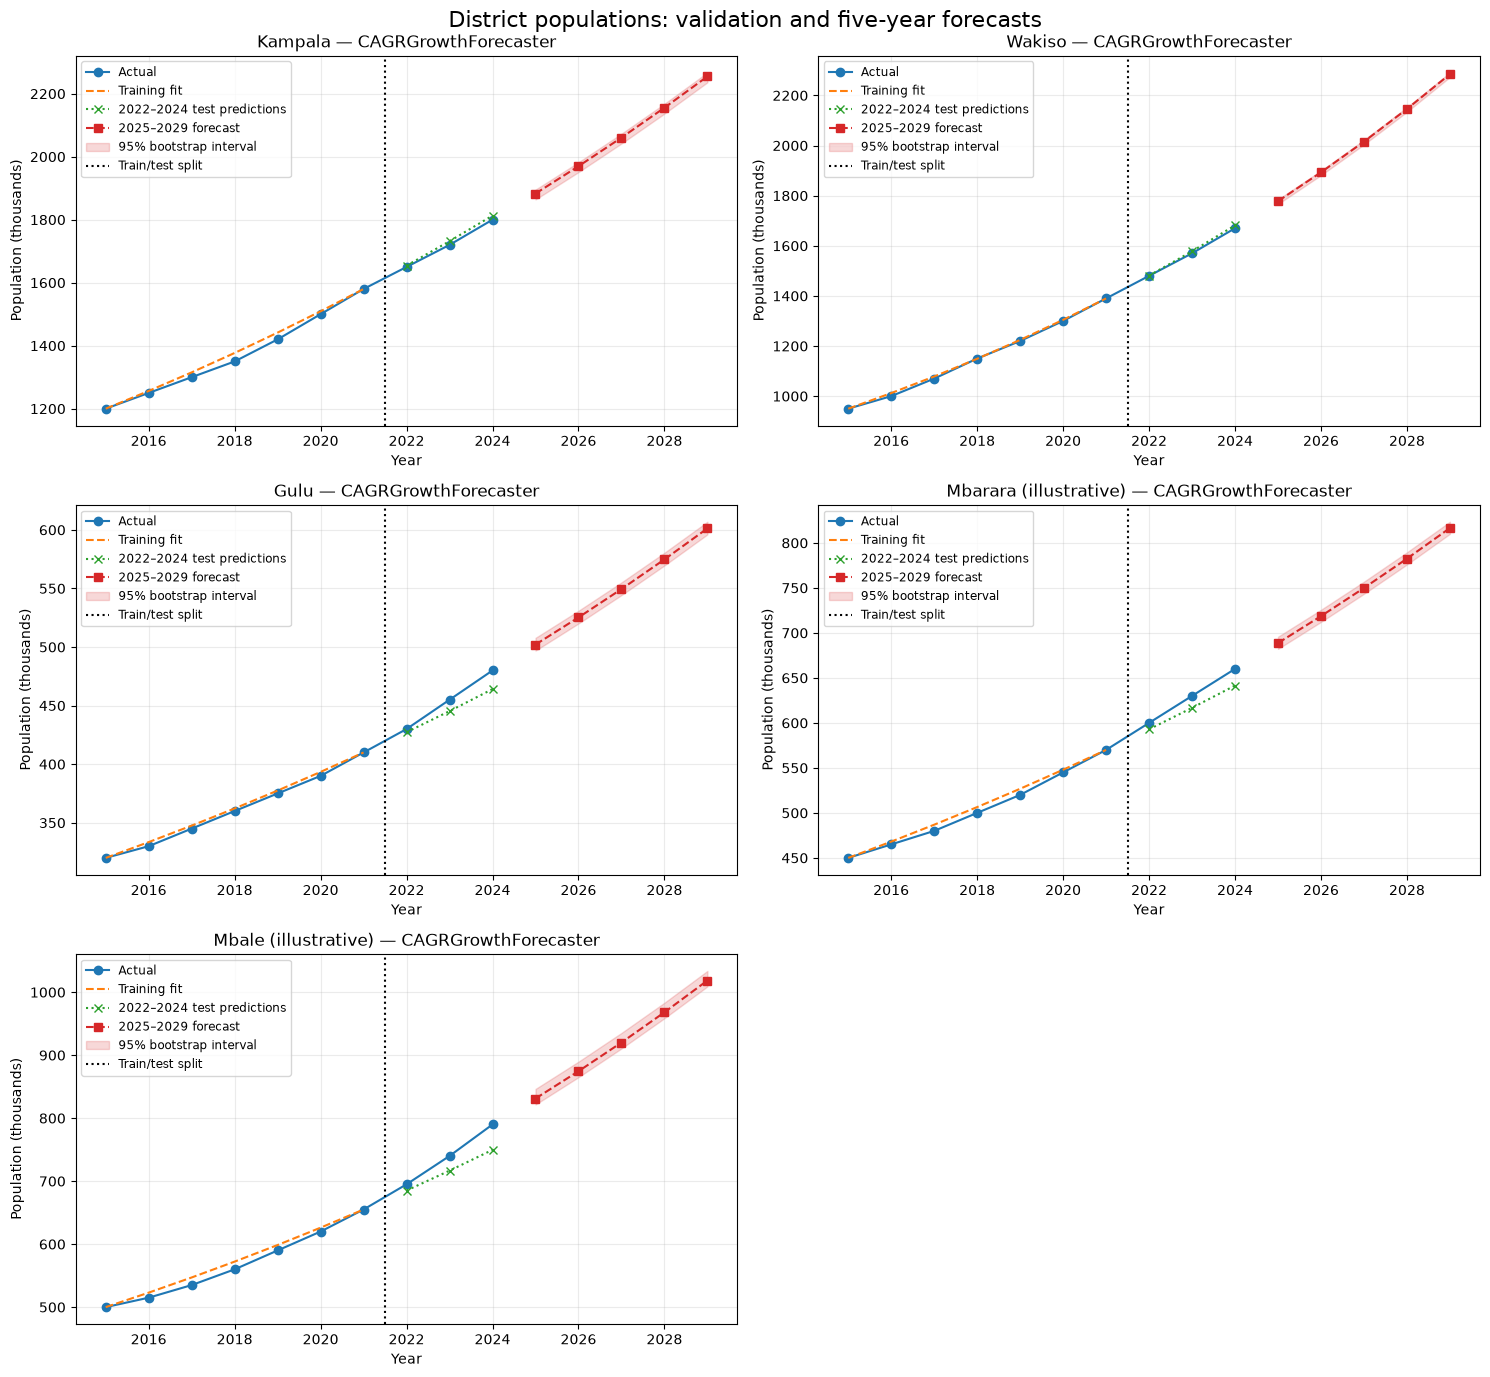

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14), squeeze=False)
for axis, district in zip(axes.ravel(), districts):
    name = district.district_name
    chosen = selected_models[name]
    validation_model = validation_models[name][chosen]
    axis.plot(district.years, district.population, marker="o", label="Actual")
    axis.plot(
        district.years[:train_size],
        validation_model.predict(district.years[:train_size]),
        linestyle="--", label="Training fit",
    )
    axis.plot(
        test_years, validation_model.predict(test_years),
        marker="x", linestyle=":", label="2022–2024 test predictions",
    )
    axis.plot(
        forecast_years, forecasts[name], marker="s", linestyle="--",
        color="tab:red", label="2025–2029 forecast",
    )
    lower, upper = prediction_intervals[name]
    axis.fill_between(
        forecast_years, lower, upper, color="tab:red", alpha=0.18,
        label="95% bootstrap interval",
    )
    axis.axvline(2021.5, color="black", linestyle=":", label="Train/test split")
    axis.set(title=f"{name} — {chosen}", xlabel="Year", ylabel="Population (thousands)")
    axis.grid(alpha=0.25)
    axis.legend(fontsize="small")
for axis in axes.ravel()[len(districts):]:
    axis.set_visible(False)
fig.suptitle("District populations: validation and five-year forecasts", fontsize=16)
fig.tight_layout()
plt.show()


## 9. Conclusions and limitations

The final cell summarizes findings produced by the calculations above.

### Critical assessment of the Fibonacci model
Successive ratios F(n+1)/F(n) converge to the golden ratio (~1.618). Applied as an annual population multiplier, that implies growth approaching **61.8% per year**. This assumption is not estimated from district observations and is not defensible for ordinary population planning unless independent evidence supports such explosive growth. Treat this as a comparison model, not a planning assumption.

### Planning caution
These are deterministic extrapolations from short illustrative series, not official projections. Before committing budgets, planners should consult official demographic projections, test different school-age shares, and audit existing classroom capacity. Bootstrap intervals only reflect the limited historical residual pattern.


In [9]:
print(f"Fastest relative growth: {fastest_district} ({growth_results[fastest_district]['CAGR']:.2f}% CAGR).")
best_model_counts = {}
for name, model_name in selected_models.items():
    best_model_counts[model_name] = best_model_counts.get(model_name, 0) + 1
print("Best validation model by district:")
for name, model_name in selected_models.items():
    print(f"  {name}: {model_name}")
print(f"Model selection counts: {best_model_counts}")
print("Additional classrooms estimated by 2029:")
for name, result in planning_results.items():
    print(f"  {name}: {result['additional classrooms']:,}")
print(
    "\nConclusion: select models using held-out performance, then treat forecasts as "
    "planning scenarios rather than certainties. Classroom estimates depend on the "
    "fixed 18% school-age share and 53-pupil capacity assumptions. The short series "
    "and historical residuals cannot capture every demographic or infrastructure risk."
)


Fastest relative growth: Wakiso (6.47% CAGR).
Best validation model by district:
  Kampala: CAGRGrowthForecaster
  Wakiso: CAGRGrowthForecaster
  Gulu: CAGRGrowthForecaster
  Mbarara (illustrative): CAGRGrowthForecaster
  Mbale (illustrative): CAGRGrowthForecaster
Model selection counts: {'CAGRGrowthForecaster': 5}
Additional classrooms estimated by 2029:
  Kampala: 1,544
  Wakiso: 2,088
  Gulu: 412
  Mbarara (illustrative): 531
  Mbale (illustrative): 776

Conclusion: select models using held-out performance, then treat forecasts as planning scenarios rather than certainties. Classroom estimates depend on the fixed 18% school-age share and 53-pupil capacity assumptions. The short series and historical residuals cannot capture every demographic or infrastructure risk.
